# 📊 Dataset Information

**Note:** The dataset for this project is **not included in this repository** to keep the repository lightweight.  

You can download the dataset from **Kaggle** using the link below:  

[Download The Student Performace Dataset](https://www.kaggle.com/datasets/alokxyadav/student-performance-and-academic-analytics-dataset?select=student_performance_academic_analytics.csv)  

Please make sure to place the downloaded CSV file in the same directory as this notebook before running any code.

# Importing

## Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

## Import CSV And convert to DataFrame

In [2]:
df = pd.read_csv('student_performance_academic_analytics.csv')

# Preprocessing

## Frist five row

In [3]:
df.head()

,Student_ID,Grade_Level,Study_Hours,Attendance,Sleep_Hours,Participation_Level,Extra_Tutoring,Internet_Access,Previous_Exam_Score,Assignment_Score,Exam_Score,Letter_Grade,Pass_Fail
0,STU00001,Grade 9,8.6,72.7,6.3,3,No,Yes,57.4,68.3,74.0,C,Pass
1,STU00002,Grade 11,11.3,67.2,6.6,2,No,Yes,52.4,66.3,46.7,F,Fail
2,STU00003,Grade 10,6.2,91.3,8.3,2,No,Yes,76.7,63.4,71.3,C,Pass
3,STU00004,Grade 10,10.4,73.6,7.9,1,Yes,Yes,75.0,68.5,69.6,C,Pass
4,STU00005,Grade 10,4.7,79.3,8.6,3,No,Yes,66.2,58.9,40.8,F,Fail


## last Five row

In [4]:
df.tail()

,Student_ID,Grade_Level,Study_Hours,Attendance,Sleep_Hours,Participation_Level,Extra_Tutoring,Internet_Access,Previous_Exam_Score,Assignment_Score,Exam_Score,Letter_Grade,Pass_Fail
1995,STU01996,Grade 11,3.5,90.1,7.7,2,No,Yes,63.8,53.5,63.6,C,Pass
1996,STU01997,Grade 11,2.2,94.3,7.4,4,No,Yes,46.5,64.0,52.1,D,Pass
1997,STU01998,Grade 10,19.3,85.9,9.0,3,Yes,Yes,66.6,90.4,73.4,C,Pass
1998,STU01999,Grade 9,6.9,84.6,6.6,3,No,Yes,70.8,50.9,57.2,D,Pass
1999,STU02000,Grade 12,11.9,64.9,6.3,4,No,Yes,79.6,63.7,54.3,D,Pass


## Shape of our dataset

In [5]:
df.shape

(2000, 13)

## List out all columns

In [6]:
df.columns

Index(['Student_ID', 'Grade_Level', 'Study_Hours', 'Attendance', 'Sleep_Hours',
       'Participation_Level', 'Extra_Tutoring', 'Internet_Access',
       'Previous_Exam_Score', 'Assignment_Score', 'Exam_Score', 'Letter_Grade',
       'Pass_Fail'],
      dtype='object')

## Datatype of each columns

In [7]:
df.dtypes

Student_ID              object
Grade_Level             object
Study_Hours            float64
Attendance             float64
Sleep_Hours            float64
Participation_Level      int64
Extra_Tutoring          object
Internet_Access         object
Previous_Exam_Score    float64
Assignment_Score       float64
Exam_Score             float64
Letter_Grade            object
Pass_Fail               object
dtype: object

## Information of all Columns

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Student_ID           2000 non-null   object 
 1   Grade_Level          2000 non-null   object 
 2   Study_Hours          2000 non-null   float64
 3   Attendance           1960 non-null   float64
 4   Sleep_Hours          1937 non-null   float64
 5   Participation_Level  2000 non-null   int64  
 6   Extra_Tutoring       2000 non-null   object 
 7   Internet_Access      2000 non-null   object 
 8   Previous_Exam_Score  1973 non-null   float64
 9   Assignment_Score     2000 non-null   float64
 10  Exam_Score           2000 non-null   float64
 11  Letter_Grade         2000 non-null   object 
 12  Pass_Fail            2000 non-null   object 
dtypes: float64(6), int64(1), object(6)
memory usage: 203.2+ KB


## Check Null Value

In [9]:
df.isnull().sum()

Student_ID              0
Grade_Level             0
Study_Hours             0
Attendance             40
Sleep_Hours            63
Participation_Level     0
Extra_Tutoring          0
Internet_Access         0
Previous_Exam_Score    27
Assignment_Score        0
Exam_Score              0
Letter_Grade            0
Pass_Fail               0
dtype: int64

## Handle missing values using median

In [10]:
df['Attendance'] = df['Attendance'].fillna(df['Attendance'].median())
df['Sleep_Hours'] = df['Sleep_Hours'].fillna(df['Sleep_Hours'].median())
df['Previous_Exam_Score'] = df['Previous_Exam_Score'].fillna(df['Previous_Exam_Score'].median())

## Check Dupicate Value

In [11]:
df.duplicated().sum()

np.int64(0)

## Summary

In [12]:
df.describe()

,Study_Hours,Attendance,Sleep_Hours,Participation_Level,Previous_Exam_Score,Assignment_Score,Exam_Score
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.00000,2000.000000
mean,8.831350,81.828000,6.983250,3.348000,64.610750,65.20920,64.137850
std,4.413068,11.829239,1.108859,0.996691,10.276365,10.12371,11.467411
min,0.500000,40.000000,4.000000,1.000000,28.800000,34.30000,22.400000
25%,5.500000,74.600000,6.200000,3.000000,57.800000,58.60000,56.400000
50%,8.200000,84.000000,7.000000,3.000000,64.000000,65.10000,63.650000
75%,11.200000,91.100000,7.700000,4.000000,70.825000,71.80000,71.300000
max,29.500000,100.000000,10.000000,5.000000,98.800000,100.00000,100.000000


# EDA

In [13]:
def show_fig():
    plt.tight_layout()
    plt.show()

plot_no = 1

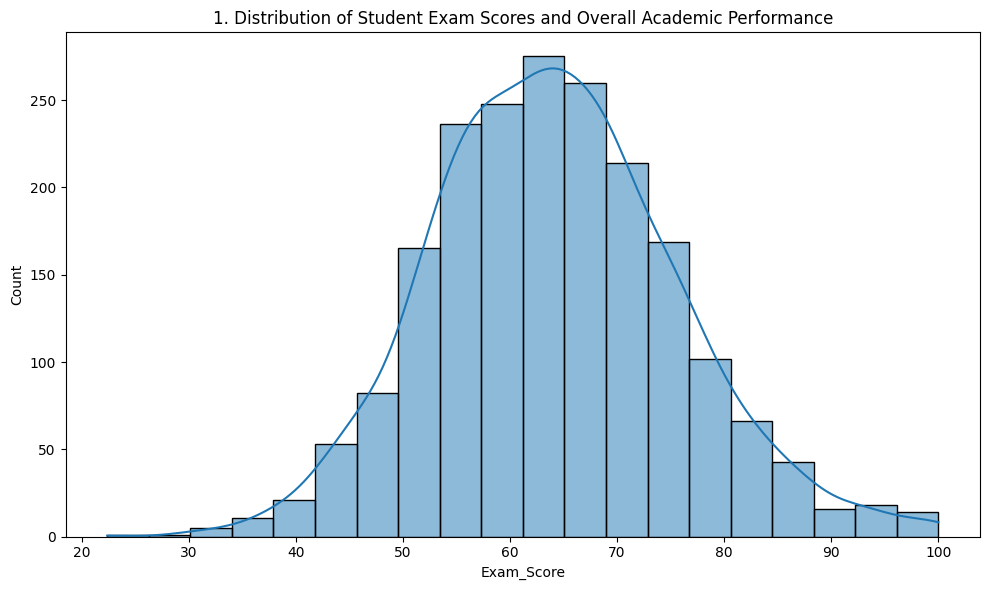

In [14]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='Exam_Score', kde=True, bins=20)
plt.title(f'{plot_no}. Distribution of Student Exam Scores and Overall Academic Performance')
show_fig()
plot_no += 1

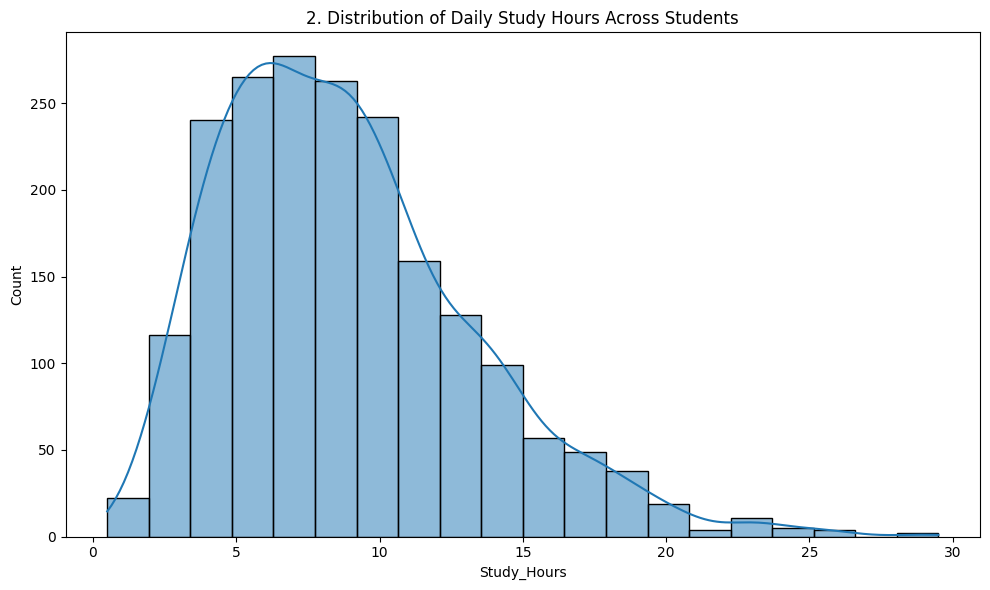

In [15]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='Study_Hours', kde=True, bins=20)
plt.title(f'{plot_no}. Distribution of Daily Study Hours Across Students')
show_fig()
plot_no += 1

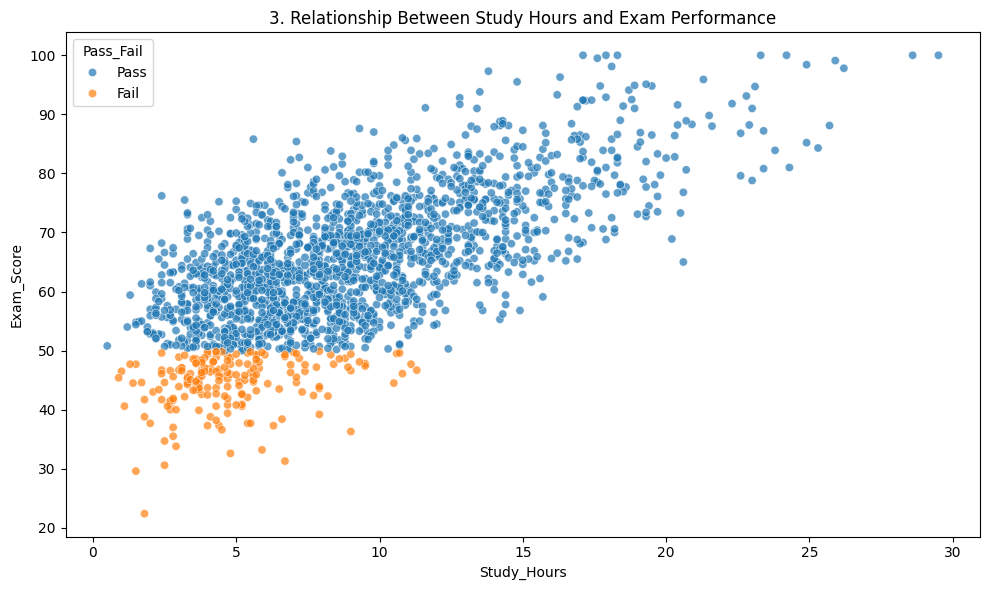

In [16]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='Study_Hours', y='Exam_Score', hue='Pass_Fail', alpha=0.7)
plt.title(f'{plot_no}. Relationship Between Study Hours and Exam Performance')
show_fig()
plot_no += 1

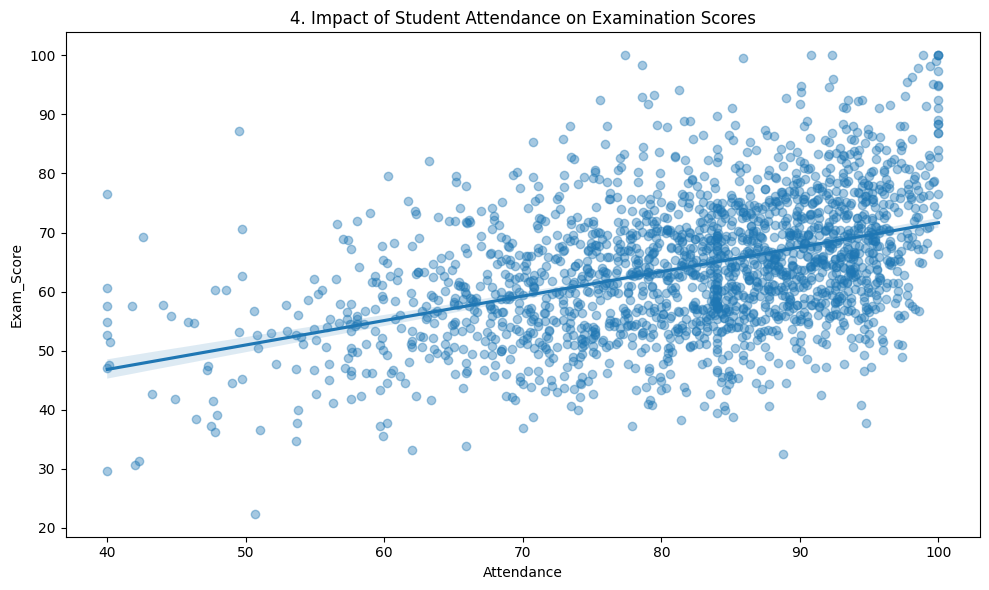

In [17]:
fig = plt.figure(figsize=(10,6))
sns.regplot(data=df, x='Attendance', y='Exam_Score', scatter_kws={'alpha':0.4})
plt.title(f'{plot_no}. Impact of Student Attendance on Examination Scores')
show_fig()
plot_no += 1

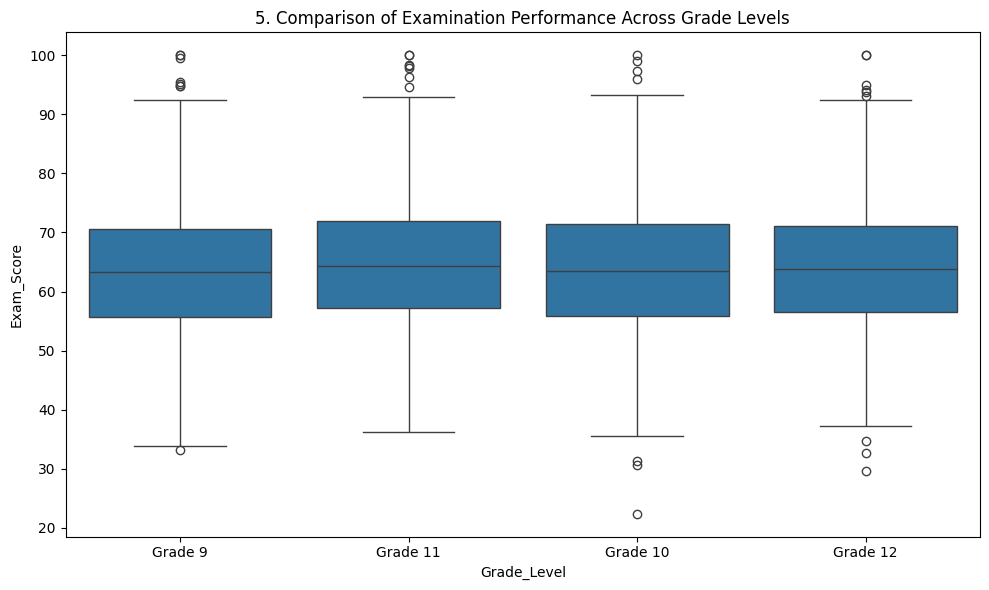

In [18]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='Grade_Level', y='Exam_Score')
plt.title(f'{plot_no}. Comparison of Examination Performance Across Grade Levels')
show_fig()
plot_no += 1

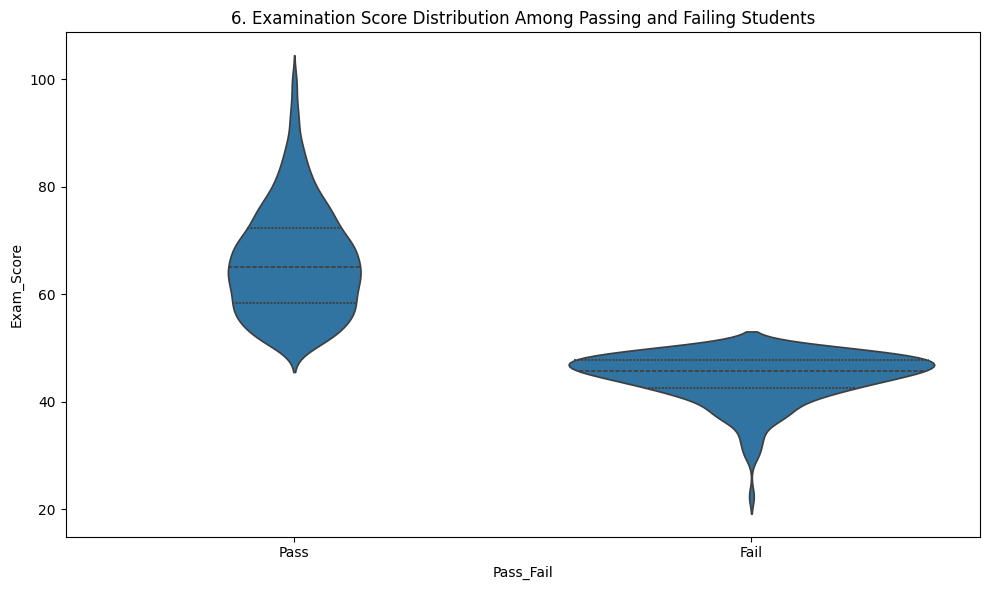

In [19]:
fig = plt.figure(figsize=(10,6))
sns.violinplot(data=df, x='Pass_Fail', y='Exam_Score', inner='quartile')
plt.title(f'{plot_no}. Examination Score Distribution Among Passing and Failing Students')
show_fig()
plot_no += 1

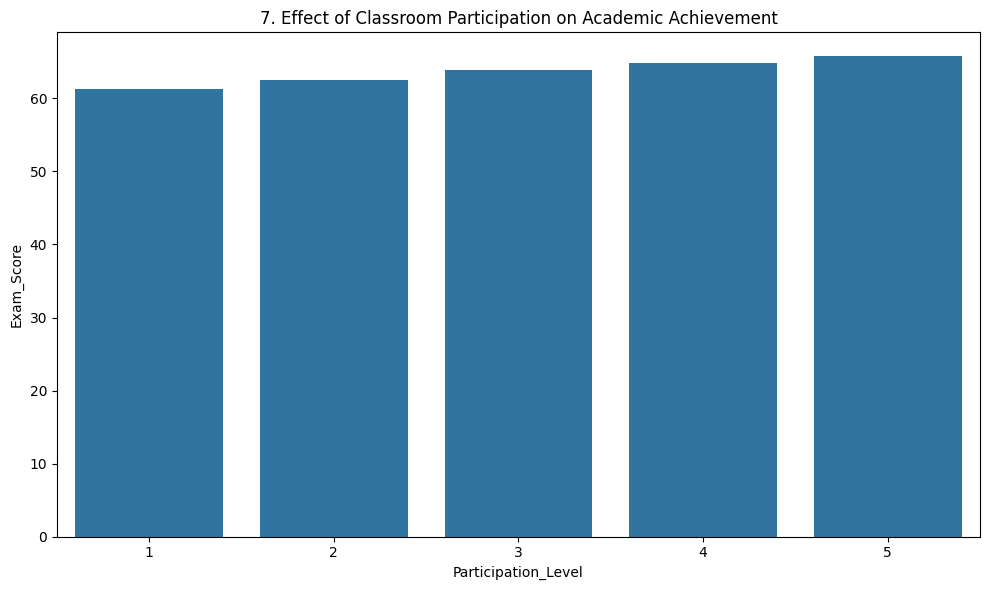

In [20]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='Participation_Level', y='Exam_Score', errorbar=None)
plt.title(f'{plot_no}. Effect of Classroom Participation on Academic Achievement')
show_fig()
plot_no += 1

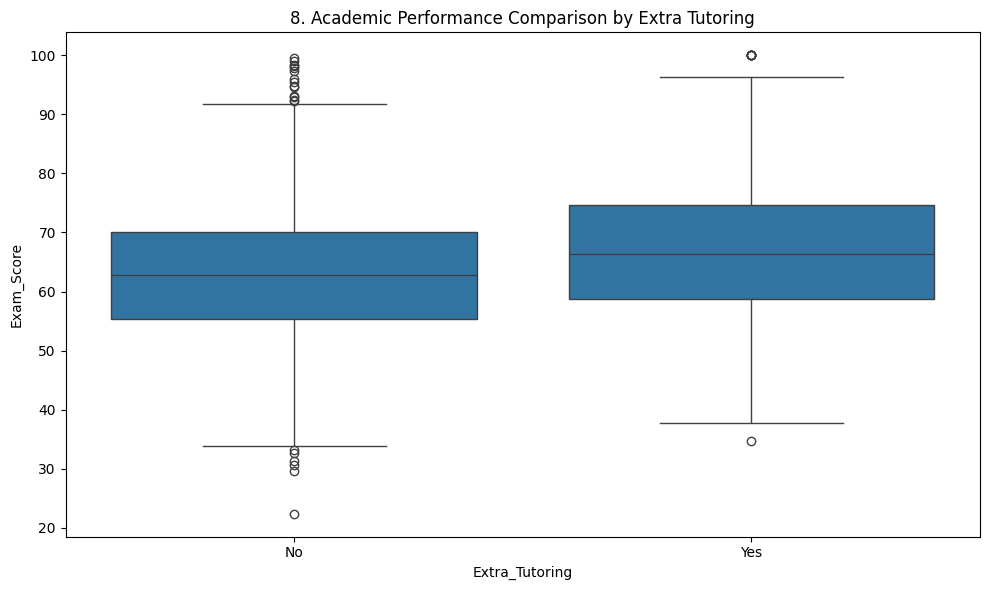

In [21]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='Extra_Tutoring', y='Exam_Score')
plt.title(f'{plot_no}. Academic Performance Comparison by Extra Tutoring')
show_fig()
plot_no += 1

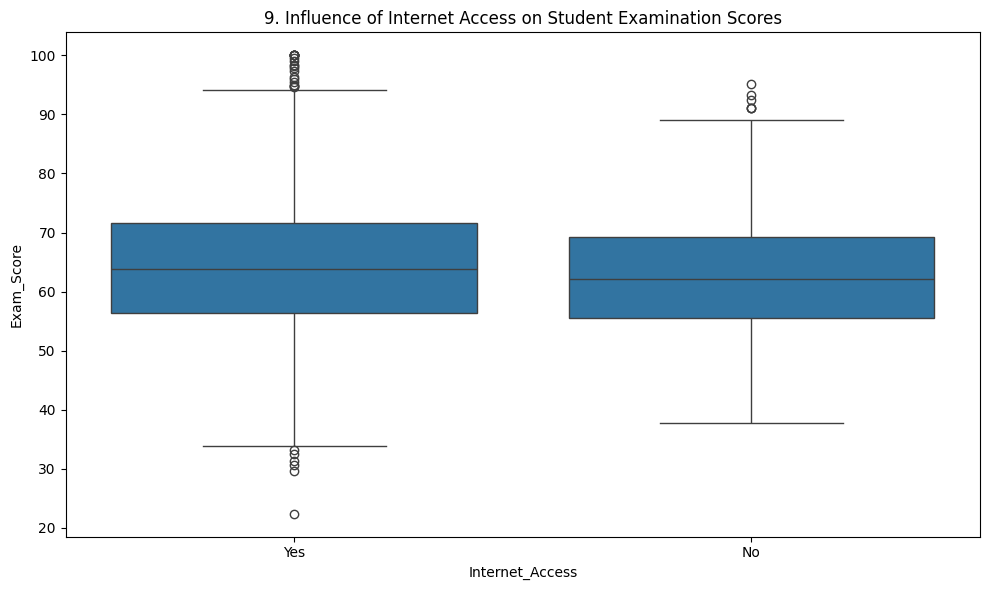

In [22]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='Internet_Access', y='Exam_Score')
plt.title(f'{plot_no}. Influence of Internet Access on Student Examination Scores')
show_fig()
plot_no += 1

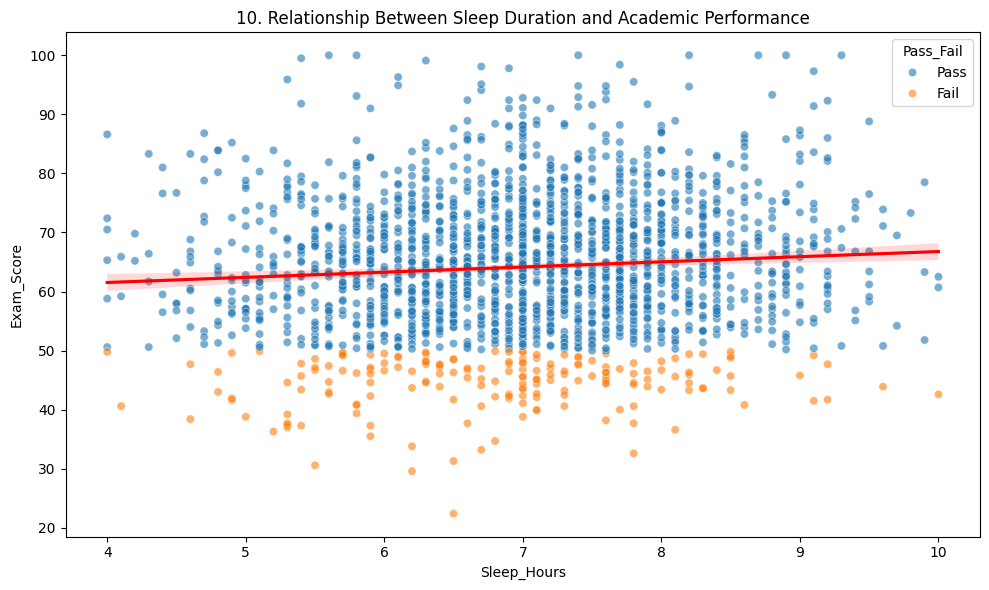

In [23]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='Sleep_Hours', y='Exam_Score', hue='Pass_Fail', alpha=0.6)
sns.regplot(data=df, x='Sleep_Hours', y='Exam_Score', scatter=False, color='red')
plt.title(f'{plot_no}. Relationship Between Sleep Duration and Academic Performance')
show_fig()
plot_no += 1

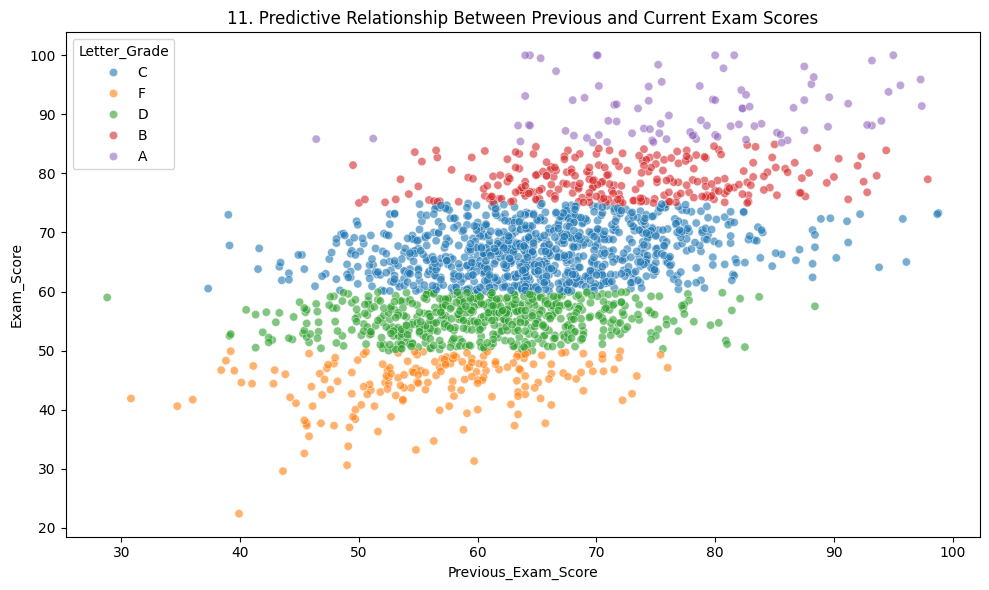

In [24]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='Previous_Exam_Score', y='Exam_Score', hue='Letter_Grade', alpha=0.6)
plt.title(f'{plot_no}. Predictive Relationship Between Previous and Current Exam Scores')
show_fig()
plot_no += 1

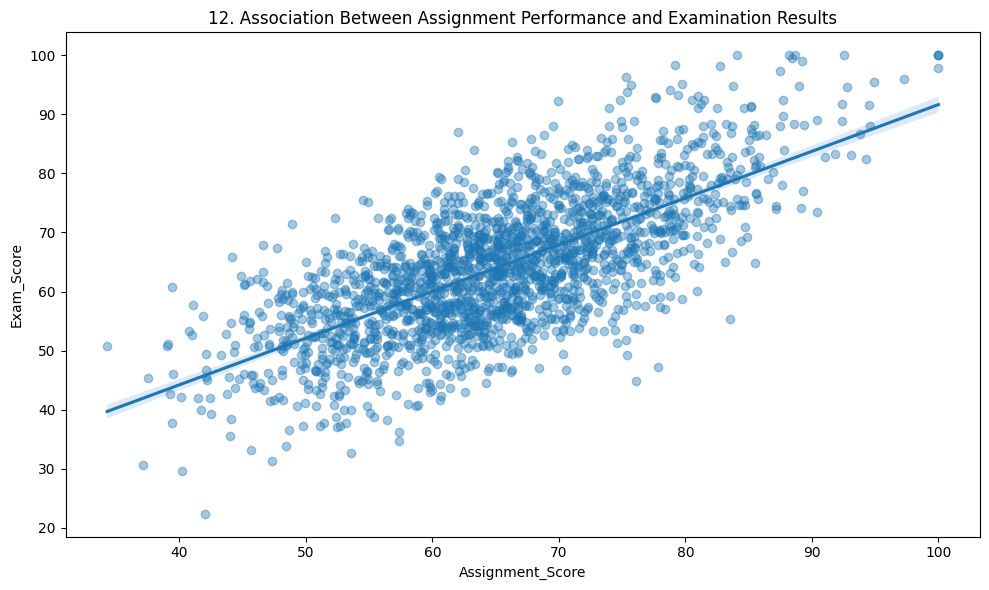

In [25]:
fig = plt.figure(figsize=(10,6))
sns.regplot(data=df, x='Assignment_Score', y='Exam_Score', scatter_kws={'alpha':0.4})
plt.title(f'{plot_no}. Association Between Assignment Performance and Examination Results')
show_fig()
plot_no += 1

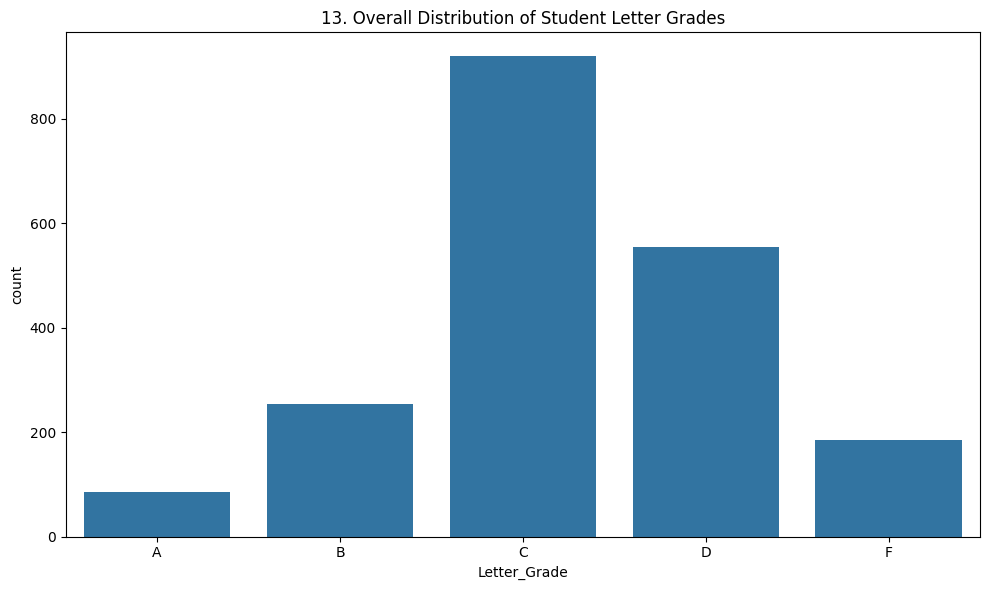

In [26]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='Letter_Grade', order=['A','B','C','D','F'])
plt.title(f'{plot_no}. Overall Distribution of Student Letter Grades')
show_fig()
plot_no += 1

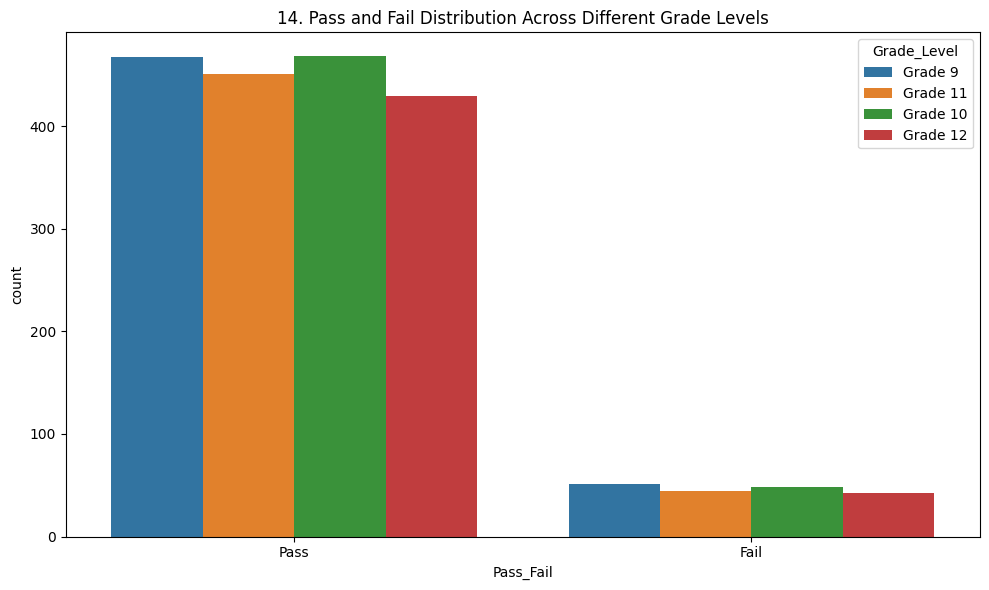

In [27]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='Pass_Fail', hue='Grade_Level')
plt.title(f'{plot_no}. Pass and Fail Distribution Across Different Grade Levels')
show_fig()
plot_no += 1

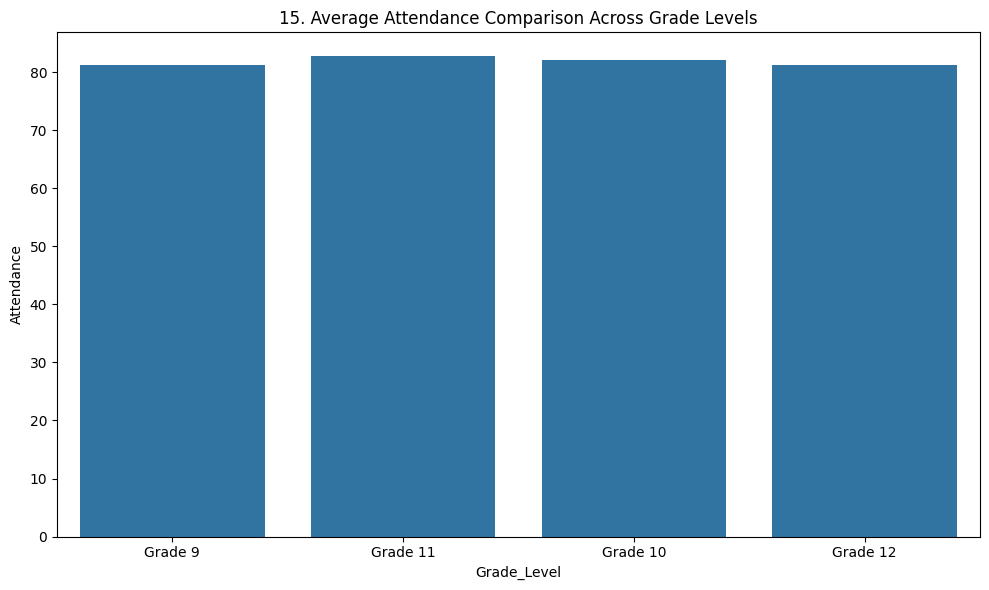

In [28]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='Grade_Level', y='Attendance', errorbar=None)
plt.title(f'{plot_no}. Average Attendance Comparison Across Grade Levels')
show_fig()
plot_no += 1

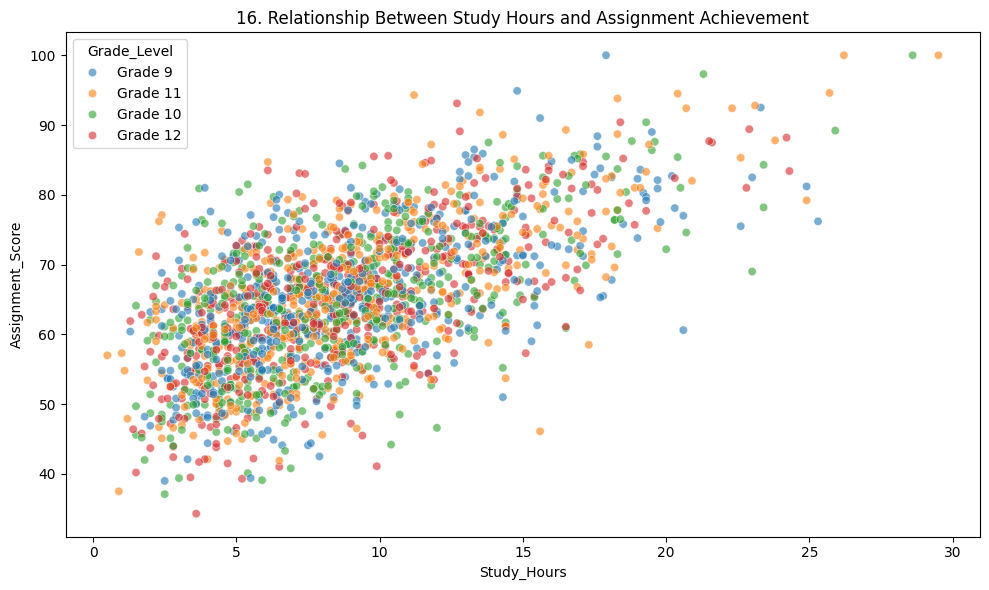

In [29]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='Study_Hours', y='Assignment_Score', hue='Grade_Level', alpha=0.6)
plt.title(f'{plot_no}. Relationship Between Study Hours and Assignment Achievement')
show_fig()
plot_no += 1

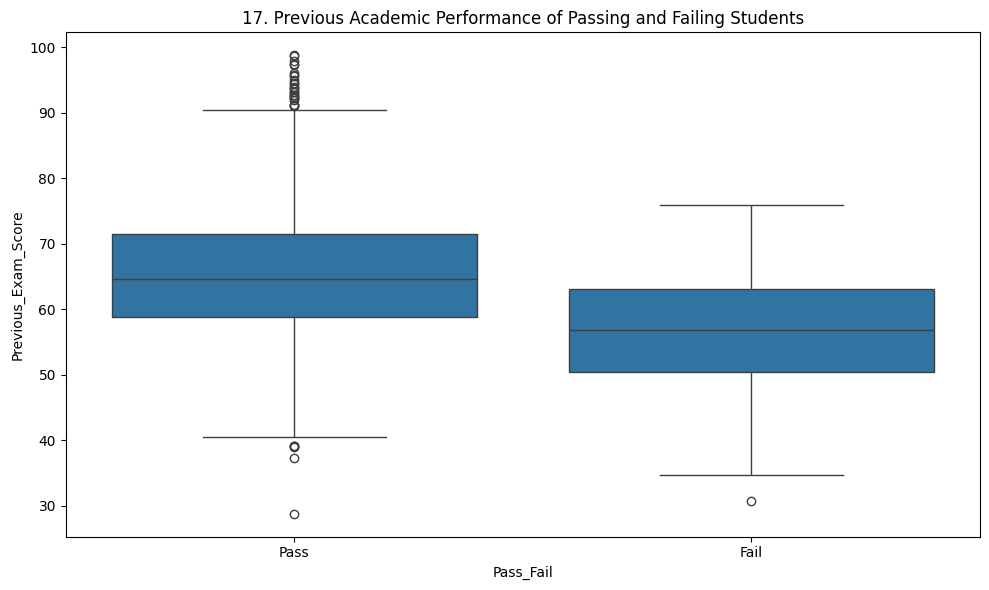

In [30]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='Pass_Fail', y='Previous_Exam_Score')
plt.title(f'{plot_no}. Previous Academic Performance of Passing and Failing Students')
show_fig()
plot_no += 1

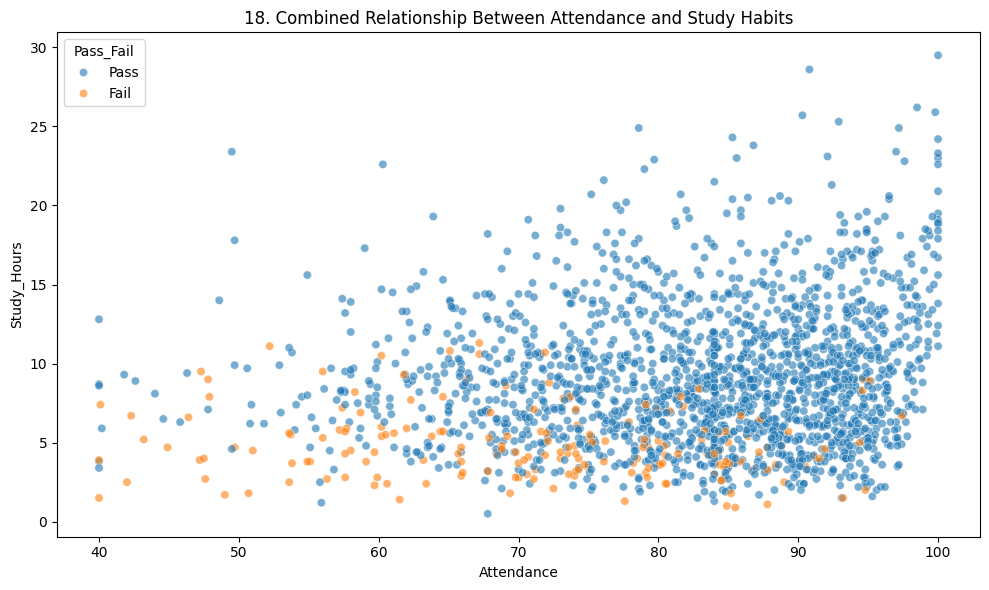

In [31]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='Attendance', y='Study_Hours', hue='Pass_Fail', alpha=0.6)
plt.title(f'{plot_no}. Combined Relationship Between Attendance and Study Habits')
show_fig()
plot_no += 1

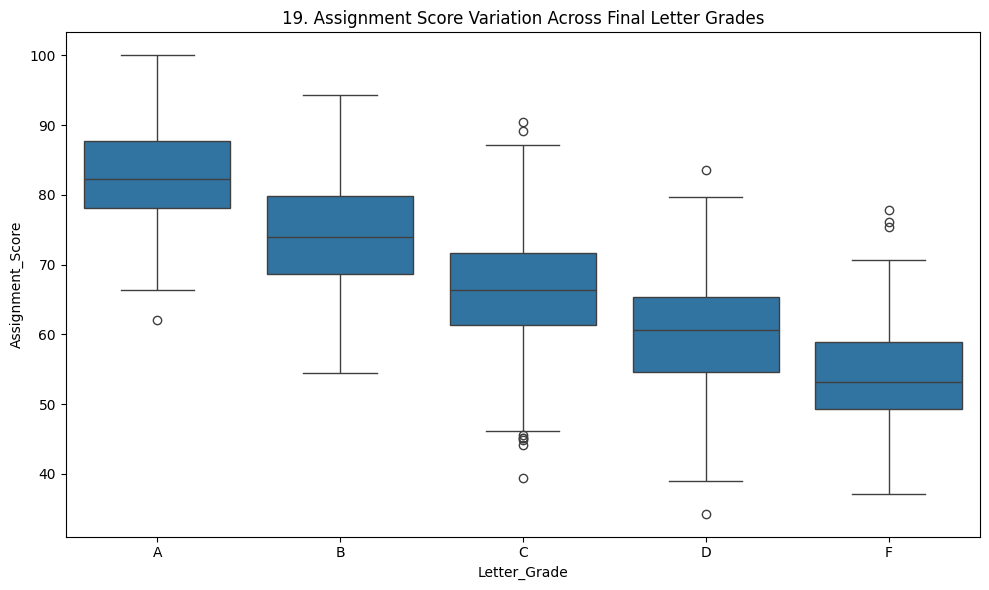

In [32]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='Letter_Grade', y='Assignment_Score', order=['A','B','C','D','F'])
plt.title(f'{plot_no}. Assignment Score Variation Across Final Letter Grades')
show_fig()
plot_no += 1

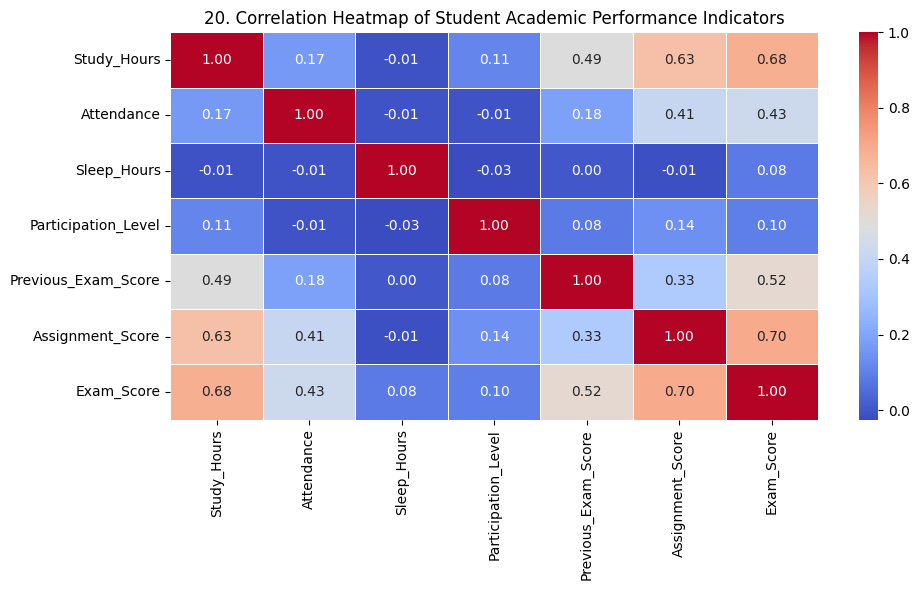

In [33]:
fig = plt.figure(figsize=(10,6))
corr = df.select_dtypes(include='number').corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title(f'{plot_no}. Correlation Heatmap of Student Academic Performance Indicators')
show_fig()
plot_no += 1

# Model Training

## Select features and target

In [34]:
X = df.drop(columns=['Student_ID', 'Exam_Score', 'Letter_Grade', 'Pass_Fail'])
y = df['Exam_Score']

## Convert categorical features into numerical features

In [35]:
X = pd.get_dummies(X, drop_first=True)

## Handle missing values

In [36]:
X = X.fillna(X.median())

## Split dataset

In [37]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## Create model

In [38]:
model = GradientBoostingRegressor(random_state=42)

## Define hyperparameter tuning

In [39]:
params = {
    'n_estimators': [100, 200, 300, 400],
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'max_depth': [2, 3, 4, 5],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'subsample': [0.7, 0.8, 0.9, 1.0]
}

## Find best parameters

In [40]:
search = RandomizedSearchCV(
    model,
    params,
    n_iter=25,
    cv=5,
    scoring='r2',
    random_state=42,
    n_jobs=-1
)

## Train optimized model

In [41]:
search.fit(X_train, y_train)
best_model = search.best_estimator_

## Predict test data

In [42]:
y_pred = best_model.predict(X_test)

## Calculate evaluation metrics

In [43]:
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

## Print model performance

In [44]:
print("Best Parameters:", search.best_params_)
print("R2 Accuracy:", round(r2 * 100, 2), "%")
print("MAE:", round(mae, 3))
print("RMSE:", round(rmse, 3))

Best Parameters: {'subsample': 0.7, 'n_estimators': 400, 'min_samples_split': 5, 'min_samples_leaf': 4, 'max_depth': 2, 'learning_rate': 0.03}
R2 Accuracy: 66.54 %
MAE: 4.969
RMSE: 6.215


## Actual vs Predicted visualization

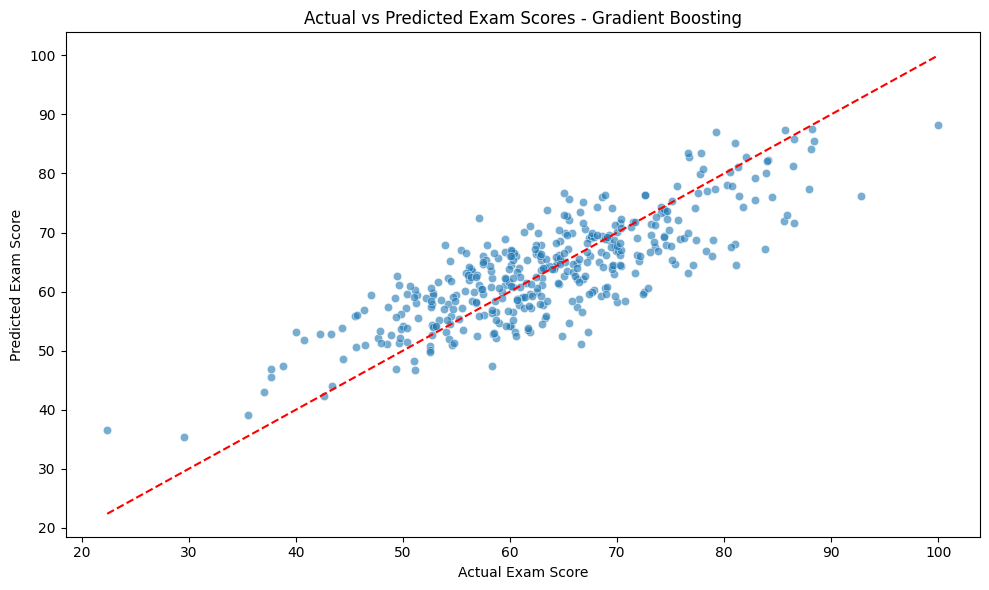

In [45]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.6)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linestyle='--'
)
plt.xlabel('Actual Exam Score')
plt.ylabel('Predicted Exam Score')
plt.title('Actual vs Predicted Exam Scores - Gradient Boosting')
show_fig()